
# Virtual river gauges from satellites — student notebook
# Stations hydrométriques virtuelles par satellite — notebook étudiant

**Congo (DR Congo) · Rewa (Fiji) · Botswana · and any river in the world** — **Congo (RD Congo) · Rewa (Fidji) · Botswana · et toute rivière du monde**

**Start here · Commencez ici :** menu **Run ▸ Run all** (Colab: **Runtime ▸ Run all**), then read from the top.
Menu **Run ▸ Run all** (Colab : **Exécution ▸ Tout exécuter**), puis lisez depuis le début.

Every result comes from **real** satellite and model data (downloaded 3 November 2026 and shipped with the `virtualgauge` package, so it works offline). About 90 minutes.
Tous les résultats viennent de **vraies** données satellitaires et de modèle (téléchargées le 3 novembre 2026 et fournies avec le package `virtualgauge`, donc utilisables hors ligne). Environ 90 minutes.

✏️ a line you can change · une ligne à modifier — 🧪 try it · à vous — 💬 questions to discuss · questions à discuter

**Contents · Sommaire** — 1 Water levels on the Congo at Kinshasa · 2 From level to discharge · 3 The Rewa, Fiji · 4 Explore the settings · 5 Explore more locations · 6 Summary  
*1 Niveaux d'eau du Congo à Kinshasa · 2 Du niveau au débit · 3 La Rewa, Fidji · 4 Explorer les réglages · 5 Explorer d'autres lieux · 6 Résumé*

[![Open in Colab · Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simreaney/virtualgauge/blob/main/Virtual_River_Gauges_Student.ipynb)


In [1]:
#@title Setup · Configuration { display-mode: "form" }
import glob, importlib.util, subprocess, sys
if importlib.util.find_spec("virtualgauge") is None:          # install once (Colab / new computer)
    REPO_URL = "https://github.com/simreaney/virtualgauge"
    wheel = sorted(glob.glob("virtualgauge-*.whl"))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", wheel[-1] if wheel else f"git+{REPO_URL}"])
import virtualgauge as vg
print(f"virtualgauge {vg.__version__} — ready · prêt")

virtualgauge 0.1.0 — ready · prêt


Choose the language of figures and messages: `"en"`, `"fr"` or `"both"`.

> Choisissez la langue des figures et des messages : `"en"`, `"fr"` ou `"both"` (les deux).

In [2]:
vg.set_language("both")   # ✏️ "en", "fr" or/ou "both"

## Part 1 — Water levels on the Congo at Kinshasa · Partie 1 — Niveaux d'eau du Congo à Kinshasa

A **virtual station** is a place where satellites measure the same river again and again. Here we combine two:
**ICESat-2** (a laser, since 2018) and **SWOT** (a radar that maps whole rivers, since 2023). One line builds the station:

> Une **station virtuelle** est un endroit où les satellites mesurent la même rivière encore et encore. Nous en
> combinons deux : **ICESat-2** (un laser, depuis 2018) et **SWOT** (un radar qui cartographie des rivières entières,
> depuis 2023). Une ligne construit la station :

In [3]:
congo = vg.build_station("congo_kinshasa")
congo

Virtual station: Congo – Kinshasa · Station virtuelle : Congo – Kinshasa
ICESat-2: 21 water levels from 6 225 points (2019-02-10 → 2025-07-29). · ICESat-2 : 21 niveaux d'eau à partir de 6 225 points (2019-02-10 → 2025-07-29).
SWOT reach 13217000081: 62 of 108 observations kept (2023-08-31 → 2026-10-26). · Tronçon SWOT 13217000081 : 62 observations gardées sur 108 (2023-08-31 → 2026-10-26).
ICESat-2 − SWOT = -0.11 m (median of 5 near-simultaneous passes). · ICESat-2 − SWOT = -0.11 m (médiane de 5 passages quasi simultanés).
Data: saved copy in your cache folder, downloaded 2026-11-03. · Données : copie enregistrée dans votre dossier cache, téléchargée le 2026-11-03.
Next: .map(), .cleaning(), .slope(), .swot(), .levels(), .rating() · Ensuite : .map(), .cleaning(), .slope(), .swot(), .levels(), .rating()

### 1.1 Where is it? · Où est-elle ?

The white outline is the **water mask** around the river centre-line; orange dots are ICESat-2 laser points. Switch to the satellite image with the layer button.

> Le contour blanc est le **masque d'eau** autour de la ligne centrale ; les points orange sont les points laser ICESat-2. Passez à l'image satellite avec le bouton des couches.

In [4]:
congo.map()

### 1.2 Step 1 — Raw laser points · Étape 1 — Points laser bruts

Every point is a water height measured by ICESat-2, in metres above the **EGM2008 geoid** (≈ mean sea level), not above your gauge zero.

> Chaque point est une hauteur d'eau mesurée par ICESat-2, en mètres au-dessus du **géoïde EGM2008** (≈ niveau moyen des mers), pas au-dessus du zéro de votre échelle.

Step 1 — Raw ICESat-2 points · Étape 1 — Points ICESat-2 bruts
6 520 water-surface points from 27 satellite passes, 2018-11-11 → 2025-12-08. · 6 520 points de surface d'eau issus de 27 passages, 2018-11-11 → 2025-12-08.
Most points form a band — the river. Why might some sit metres above it? · La plupart des points forment une bande — la rivière. Pourquoi certains sont-ils des mètres au-dessus ?
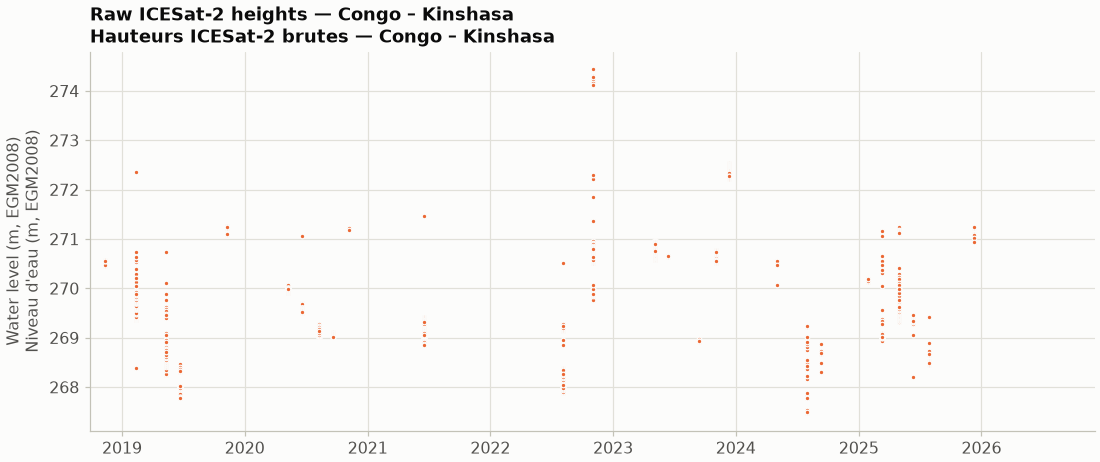

In [5]:
congo.raw_points()

💬 **What do you notice?**

- Most points form a band — the river. What could make the laser see a surface 10–40 m higher?

> 💬 **Qu'observez-vous ?**
>
> - La plupart des points forment une bande — le fleuve. Qu'est-ce qui pourrait faire voir au laser une surface 10 à 40 m plus haut ?

### 1.3 Step 2 — Cleaning · Étape 2 — Nettoyage

Points are removed for four reasons: impossible level, not a river, cloudy, or an outlier within its pass. Every removal has a written reason.

> Les points sont retirés pour quatre raisons : niveau impossible, pas une rivière, nuageux, ou valeur aberrante dans son passage. Chaque retrait a une raison écrite.

,Reason · Raison,Count · Nombre
0,kept · gardé,6225
1,cloudy · nuageux,149
2,outlier in its pass · valeur aberrante dans son passage,133

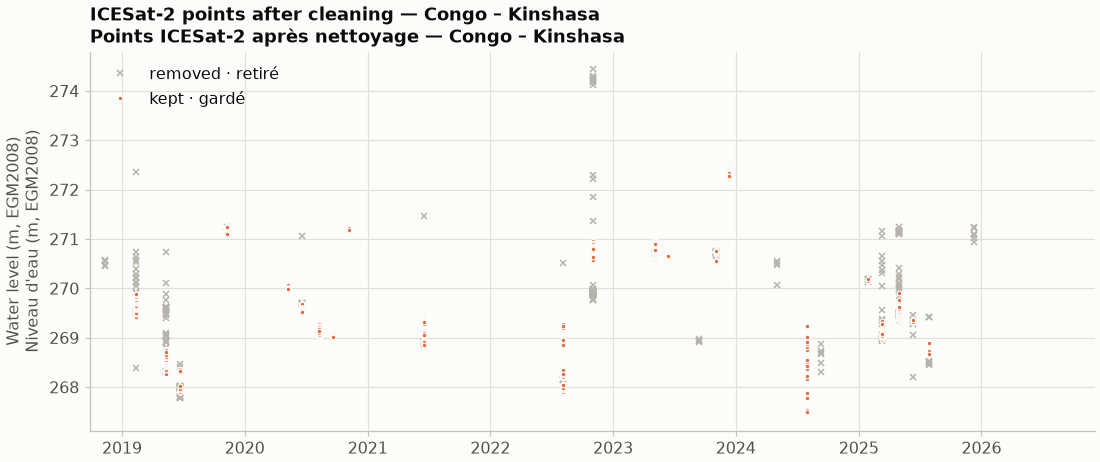

In [6]:
congo.cleaning()

💬 **What do you notice?**

- Which filter removes the most points?
- Look at the grey crosses: were any real water levels removed?

> 💬 **Qu'observez-vous ?**
>
> - Quel filtre retire le plus de points ?
> - Regardez les croix grises : de vrais niveaux d'eau ont-ils été retirés ?

### 1.4 Step 3 — The river surface slopes · Étape 3 — La surface du fleuve est en pente

Each laser pass crosses the reach at a different place. The water surface falls downstream, so the points are corrected to the middle of the reach before taking one level per pass.

> Chaque passage laser croise le tronçon à un endroit différent. La surface de l'eau descend vers l'aval : les points sont ramenés au milieu du tronçon avant de prendre un niveau par passage.

,pass_id,slope_m_per_km,n_points,span_km
0,2019-02-10_rgt669,0.106,1109,4.36
1,2019-05-12_rgt669,0.116,279,4.26
2,2019-11-09_rgt669,0.017,49,2.69
3,2021-06-18_rgt1301,0.129,259,4.54
4,2022-08-04_rgt669,0.082,94,4.26
5,2022-11-03_rgt669,0.051,1072,4.26
6,2023-05-04_rgt669,0.057,999,4.26
7,2023-12-13_rgt1301,0.081,630,2.17
8,2024-07-31_rgt669,0.343,49,4.26
9,2025-04-29_rgt669,0.008,360,7.36

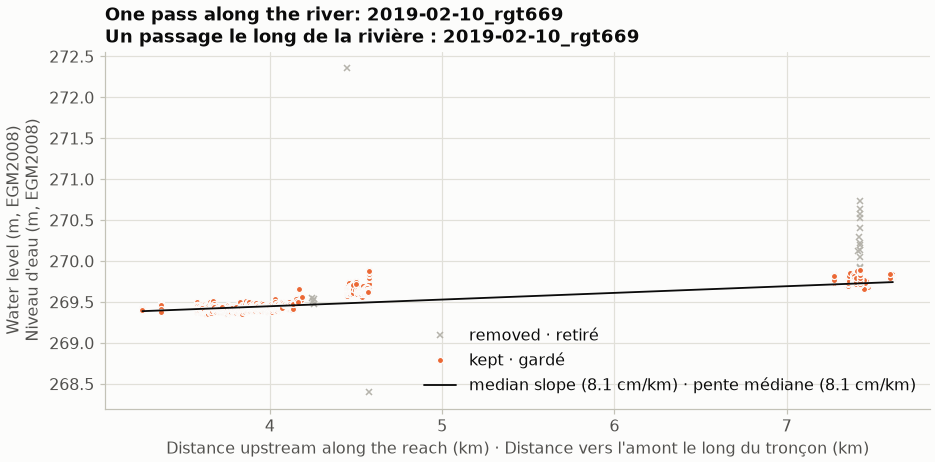

In [7]:
congo.slope()

💬 **What do you notice?**

- Is a slope of about 8 cm per km plausible for a very large river?
- Why might one pass give a much larger slope than the others? (look at its number of points)

> 💬 **Qu'observez-vous ?**
>
> - Une pente d'environ 8 cm par km est-elle plausible pour un très grand fleuve ?
> - Pourquoi un passage donne-t-il une pente bien plus forte que les autres ? (regardez son nombre de points)

,pass_id,time,wse_m,wse_u_m,n_points
0,2019-02-10_rgt669,2019-02-10 08:52:58.881074176,270,0.1,1109
1,2019-05-12_rgt669,2019-05-12 04:32:38.532051200,268,0.1,279
2,2019-06-22_rgt1301,2019-06-22 14:32:55.298259456,268,0.102,24
3,2019-11-09_rgt669,2019-11-09 19:52:14.638722048,271,0.1,49
4,2020-05-09_rgt669,2020-05-09 11:11:48.098031616,270,0.1,973
5,2020-06-19_rgt1301,2020-06-19 21:12:08.011817984,270,0.1,156
6,2020-08-08_rgt669,2020-08-08 06:51:32.872327424,269,0.101,52
7,2020-09-18_rgt1301,2020-09-18 16:51:55.656702208,269,0.1,24
8,2021-06-18_rgt1301,2021-06-18 03:51:29.376819968,269,0.1,259
9,2022-08-04_rgt669,2022-08-04 20:10:42.372601856,268,0.101,94

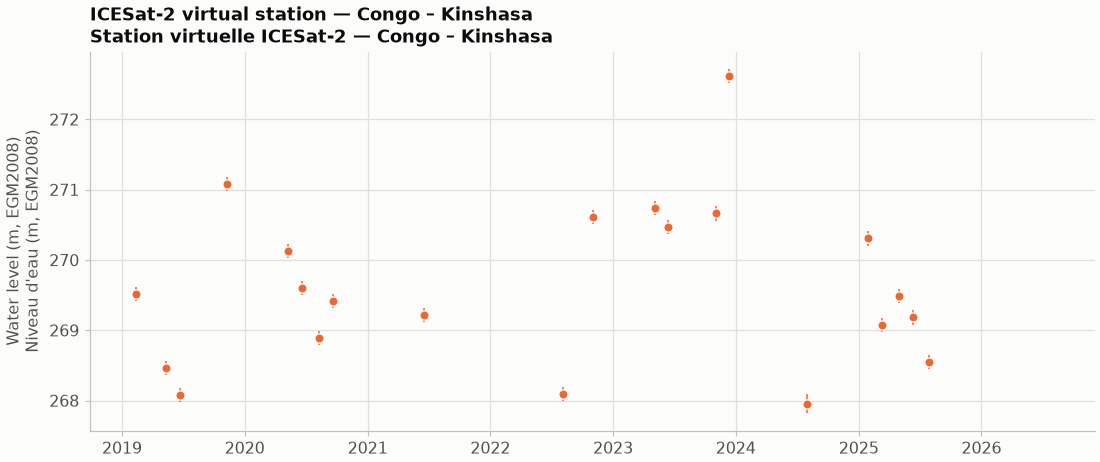

In [8]:
congo.icesat_levels()

### 1.5 Step 4 — SWOT · Étape 4 — SWOT

SWOT gives one level for the whole ~10 km reach at each pass. We keep good quality flags and check that **water flows downhill**: our reach cannot be higher than the reach upstream at the same moment.

> SWOT donne un niveau pour tout le tronçon de ~10 km à chaque passage. On garde les bons indicateurs de qualité et on vérifie que **l'eau descend** : notre tronçon ne peut pas être plus haut que l'amont au même moment.

,Reason · Raison,Count · Nombre
0,kept · gardé,62
1,quality flag reach_q > 1 · indicateur reach_q > 1,46

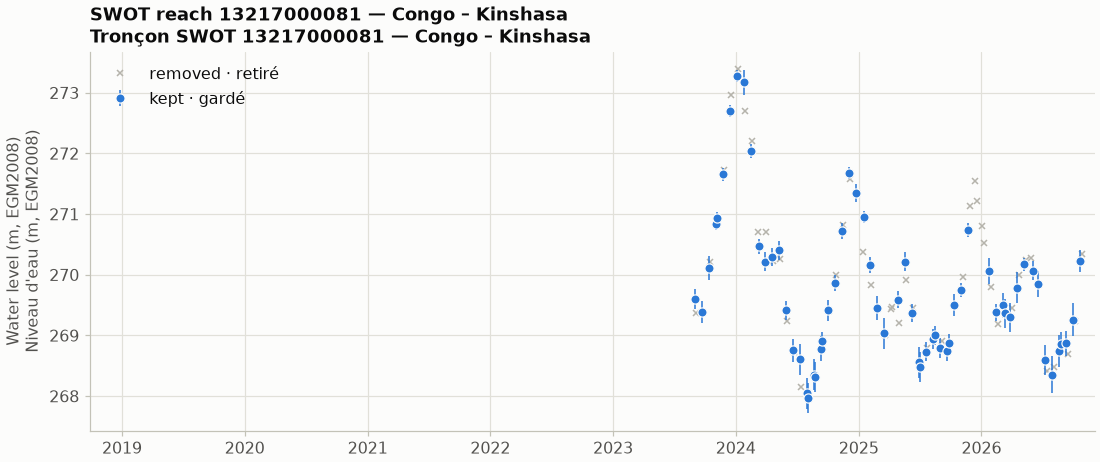

In [9]:
congo.swot()

💬 **What do you notice?**

- How many SWOT levels per year do we get, compared with ICESat-2?
- Why do you think so many observations fail the quality flags?

> 💬 **Qu'observez-vous ?**
>
> - Combien de niveaux SWOT par an obtient-on, comparé à ICESat-2 ?
> - Pourquoi, à votre avis, tant d'observations échouent-elles aux indicateurs de qualité ?

### 1.6 Step 5 — Two satellites, one station · Étape 5 — Deux satellites, une station

When both satellites passed within 3 days, we compare them and shift ICESat-2 onto SWOT.

> Quand les deux satellites sont passés à moins de 3 jours d'intervalle, on les compare et on ramène ICESat-2 sur SWOT.

In [10]:
congo.agreement()

,time,wse_m,time_swot,wse_swot,days_apart,difference_m
13,2023-11-01 22:28:43.847729920,271,2023-11-02 00:54:25,271,-0.1,-0.184
14,2023-12-13 08:29:03.856563712,273,2023-12-13 18:24:34,273,-0.4,-0.083
15,2024-07-31 09:27:17.752075264,268,2024-07-30 06:40:27,268,1.1,-0.098
18,2025-04-29 20:26:08.591902720,269,2025-04-27 12:26:29,270,2.3,-0.109
19,2025-06-10 06:26:20.786686208,269,2025-06-08 05:56:39,269,2,-0.184


,SWOT,ICESat-2,all
observations,62,21,83
first,2023-08-31,2019-02-10,2019-02-10
last,2026-10-21,2025-07-29,2026-10-21
per_year,19.7,3.2,10.8
median_gap_days,20.9,70.1,20.9
longest_gap_days,62.6,413,413

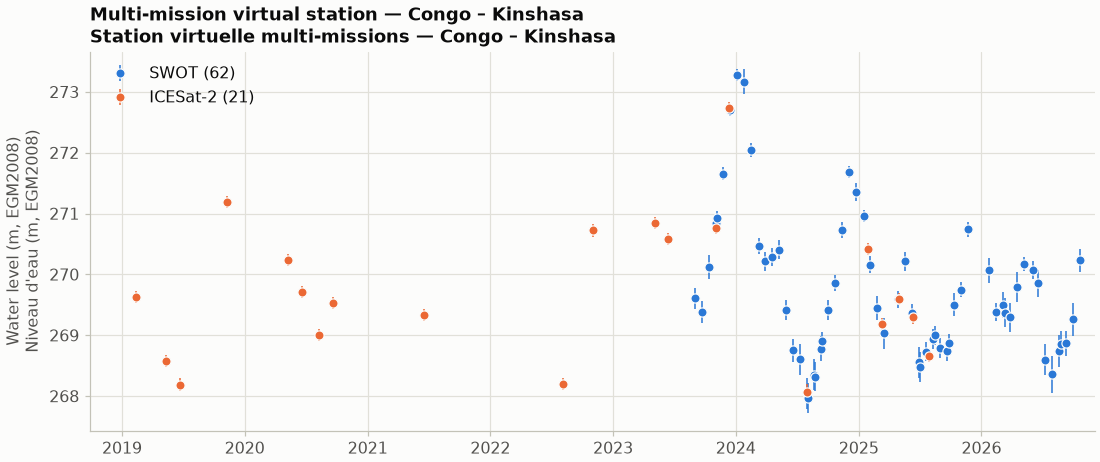

In [11]:
congo.levels()

💬 **What do you notice?**

- When are the lowest and highest levels of the year?
- Something unusual happened at the end of 2023 — what do you see?
- Is an offset from only 5 pairs reliable?

> 💬 **Qu'observez-vous ?**
>
> - Quand surviennent les niveaux les plus bas et les plus hauts de l'année ?
> - Quelque chose d'inhabituel s'est produit fin 2023 — que voyez-vous ?
> - Un décalage estimé sur seulement 5 paires est-il fiable ?

## Part 2 — From level to discharge · Partie 2 — Du niveau au débit

A **rating curve** turns water level into discharge: **Q = a · (h − h₀)ᵇ**. To fit it we need discharge on the days
the satellites looked. With no open gauge data for these years, we use the **GEOGloWS model** — and we must check it.

> Une **courbe de tarage** transforme le niveau en débit : **Q = a · (h − h₀)ᵇ**. Pour l'ajuster, il faut des débits aux
> dates des passages. Sans données de station ouvertes pour ces années, on utilise le **modèle GEOGloWS** — et il faut le vérifier.

### 2.1 The reference discharge · Le débit de référence

Step 7 — Reference discharge · Étape 7 — Débit de référence
Reference discharge: GEOGloWS model, 1940-01-01 → 2026-10-16. · Débit de référence : modèle GEOGloWS, 1940-01-01 → 2026-10-16.
Automatic GEOGloWS river lookup at this point: river 130594908, mean flow 1.1 m³/s. · Recherche automatique GEOGloWS à ce point : rivière 130594908, débit moyen 1.1 m³/s.
River chosen by hand: 130798640, mean flow 62 795 m³/s. Always check the river ID on a map. · Rivière choisie à la main : 130798640, débit moyen 62 795 m³/s. Vérifiez toujours l'identifiant sur une carte.
! This is a model, not a measurement. Your own gauge data would be better. · C'est un modèle, pas une mesure. Vos propres données de station seraient meilleures.
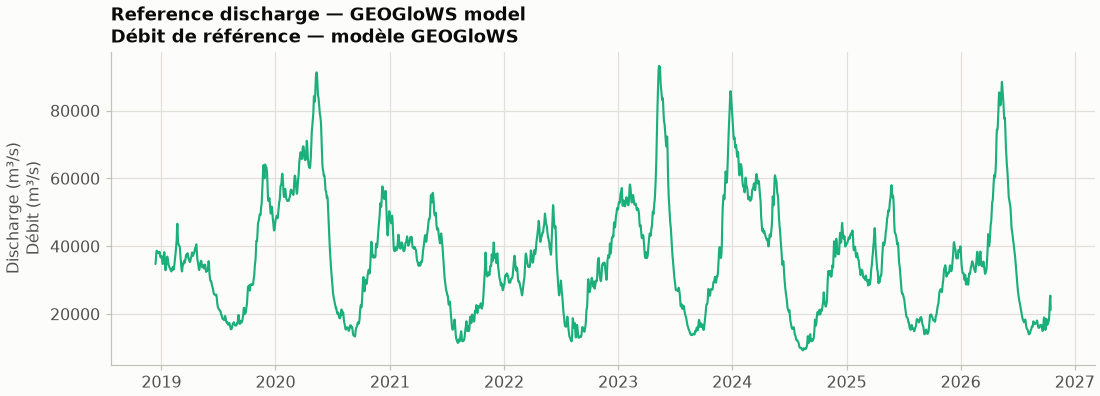

In [12]:
congo.reference_discharge()

💬 **What do you notice?**

- The automatic river lookup found a river with about 1 m³/s. Why is that a problem?

> 💬 **Qu'observez-vous ?**
>
> - La recherche automatique a trouvé une rivière d'environ 1 m³/s. Pourquoi est-ce un problème ?

### 2.2 The rating curve · La courbe de tarage

,n,r,NSE,KGE,RMSE,PBIAS %
fit,82,0.699,0.473,0.618,"12,944",-5.32

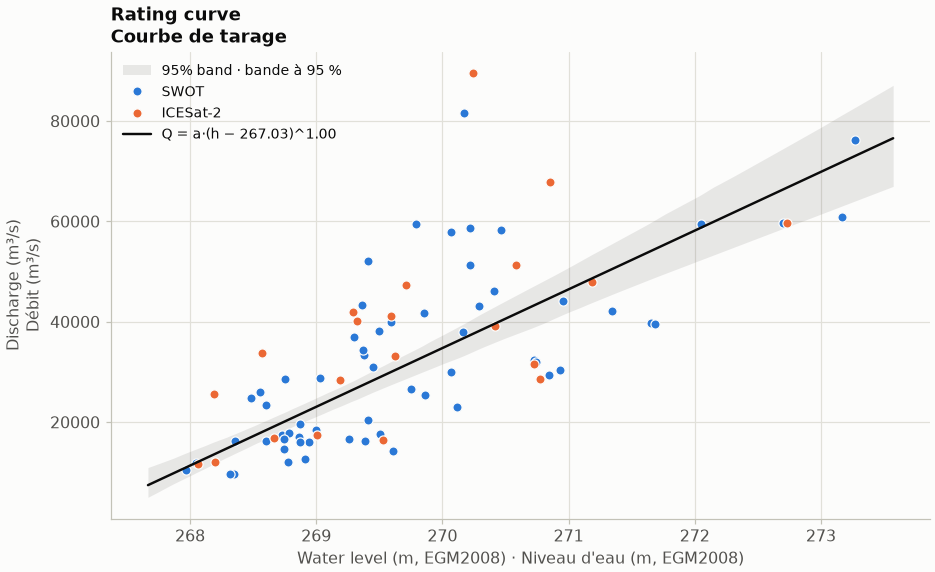

In [13]:
congo.rating()

💬 **What do you notice?**

- What does the warning “b is at its limit” tell you?
- Is NSE = 0.47 good enough for a flow gauge?

> 💬 **Qu'observez-vous ?**
>
> - Que vous dit l'avertissement « b est à sa limite » ?
> - Un NSE de 0,47 suffit-il pour une station de débit ?

### 2.3 Which months fit? · Quels mois s'ajustent ?

month,1,2,3,4,5,6,7,8,9,10,11,12
median,-4,9,32,35,87,50,-2,-20,-34,-36,-27,-13
count,5,5,7,4,7,10,8,11,8,4,9,4

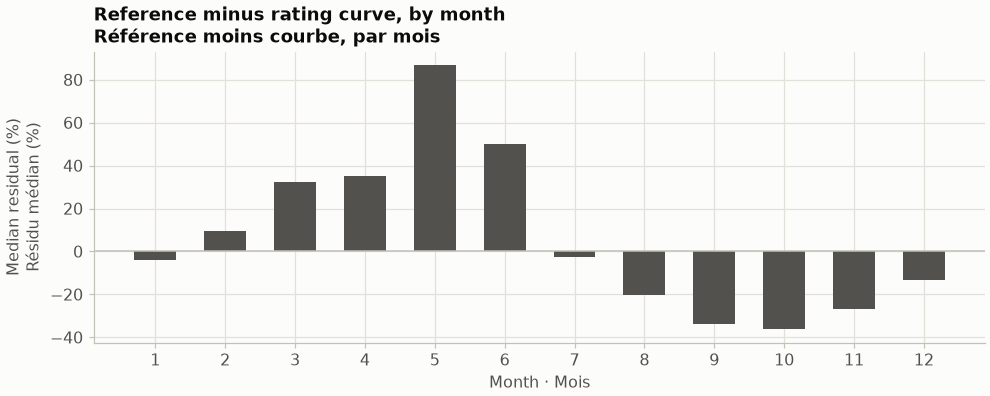

In [14]:
congo.residuals_by_month()

💬 **What do you notice?**

- Kinshasa's level is controlled by rock rapids just downstream, which do not move. So is this seasonal pattern caused by the river, or by the model?

> 💬 **Qu'observez-vous ?**
>
> - Le niveau à Kinshasa est contrôlé par des rapides rocheux juste en aval, qui ne bougent pas. Cette structure saisonnière vient-elle du fleuve ou du modèle ?

Leave out the months where the model disagrees with the satellites, and fit again:

> Excluez les mois où le modèle contredit les satellites, et ajustez à nouveau :

,n,r,NSE,KGE,RMSE,PBIAS %
all months,82,0.699,0.473,0.618,"12,944",-5.32
fit months only,54,0.94,0.882,0.911,5.24e+03,-1.89

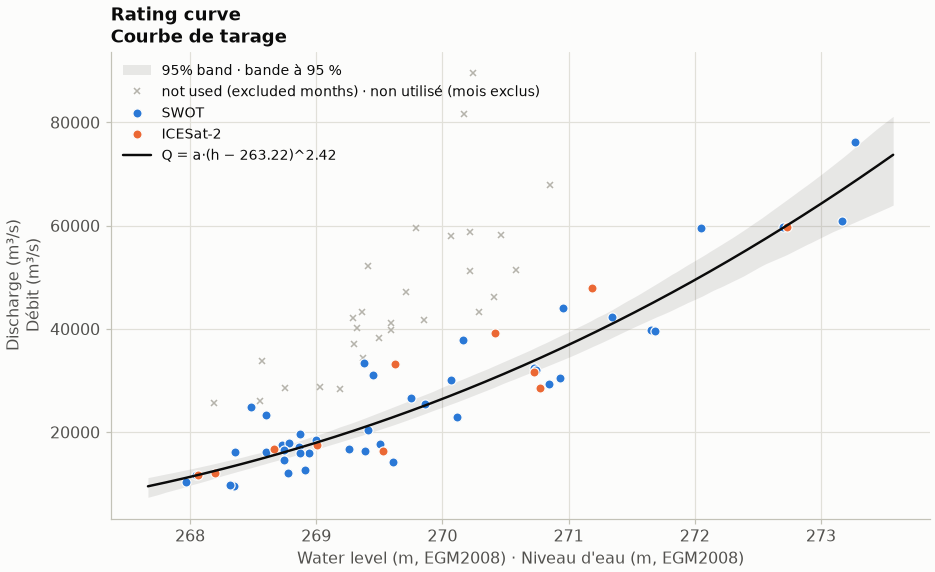

In [15]:
congo.rating(exclude_months=[3, 4, 5, 6])   # ✏️ try other months · essayez d'autres mois

### 2.4 Test on years not used for fitting · Test sur des années non utilisées

In [16]:
congo.split_test("2025-01-01")

,n,r,NSE,KGE,RMSE,PBIAS %
train,31,0.968,0.936,0.944,4.64e+03,-1.39
test,23,0.844,0.329,0.597,7.1e+03,-22.1


💬 **What do you notice?**

- The curve fits the earlier years well. Why is it worse on 2025–2026?
- What do we lose by leaving months out?

> 💬 **Qu'observez-vous ?**
>
> - La courbe s'ajuste bien aux premières années. Pourquoi est-elle moins bonne en 2025–2026 ?
> - Que perd-on en excluant des mois ?

### 2.5 Discharge and export · Débit et export

,count,mean,std,min,25%,50%,75%,max
wse_m,83,270,1.2,268,269,270,270,273
Q_m3s,83,"25,498","12,129","11,155","16,982","22,015","29,895","68,667"

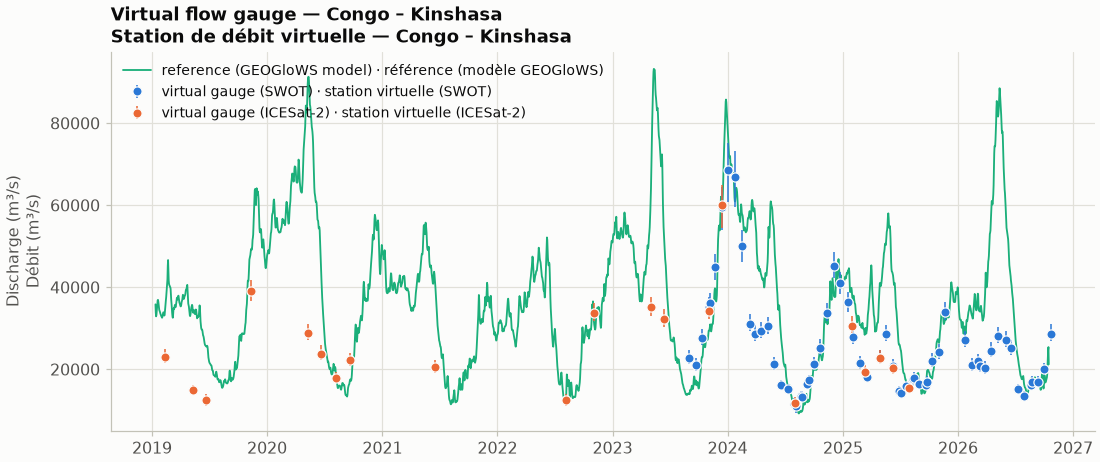

In [17]:
congo.discharge()

💬 **What do you notice?**

- The long-term mean flow measured at Kinshasa since 1903 is about 40,000 m³/s. How does our virtual gauge compare, and why?

> 💬 **Qu'observez-vous ?**
>
> - Le débit moyen mesuré à Kinshasa depuis 1903 est d'environ 40 000 m³/s. Comment notre station virtuelle se compare-t-elle, et pourquoi ?

Save the result as a CSV file for your agency (folder `outputs/`). On Colab use `congo.export(download=True)`.

> Enregistrez le résultat en CSV pour votre service (dossier `outputs/`). Sur Colab, utilisez `congo.export(download=True)`.

In [18]:
congo.export()

Export
Written: outputs/congo_kinshasa_virtual_gauge.csv · Écrit : outputs/congo_kinshasa_virtual_gauge.csv
Written: outputs/congo_kinshasa_virtual_gauge_metadata.json · Écrit : outputs/congo_kinshasa_virtual_gauge_metadata.json

## Part 3 — The Rewa, Fiji · Partie 3 — La Rewa, Fidji

The same method on a river 100–400 m wide, with cyclone floods that last hours to days, and a tidal lower course.

> La même méthode sur une rivière de 100 à 400 m de large, avec des crues cycloniques de quelques heures à quelques jours, et un cours inférieur soumis à la marée.

In [19]:
rewa = vg.build_station("rewa_fiji")
rewa

Virtual station: Rewa – Fiji · Station virtuelle : Rewa – Fiji
ICESat-2: 18 water levels from 875 points (2018-12-26 → 2025-06-17). · ICESat-2 : 18 niveaux d'eau à partir de 875 points (2018-12-26 → 2025-06-17).
SWOT reach 55200000051: 82 of 108 observations kept (2023-07-28 → 2026-10-29). · Tronçon SWOT 55200000051 : 82 observations gardées sur 108 (2023-07-28 → 2026-10-29).
ICESat-2 − SWOT = +0.07 m (median of 3 near-simultaneous passes). · ICESat-2 − SWOT = +0.07 m (médiane de 3 passages quasi simultanés).
Data: saved copy in your cache folder, downloaded 2026-11-03. · Données : copie enregistrée dans votre dossier cache, téléchargée le 2026-11-03.
Next: .map(), .cleaning(), .slope(), .swot(), .levels(), .rating() · Ensuite : .map(), .cleaning(), .slope(), .swot(), .levels(), .rating()

### 3.1 Levels and slope · Niveaux et pente

,SWOT,ICESat-2,all
observations,82,18,100
first,2023-07-28,2018-12-26,2018-12-26
last,2026-10-22,2025-06-17,2026-10-22
per_year,25.4,2.8,12.8
median_gap_days,13.4,90.8,13.4
longest_gap_days,55.1,454,454

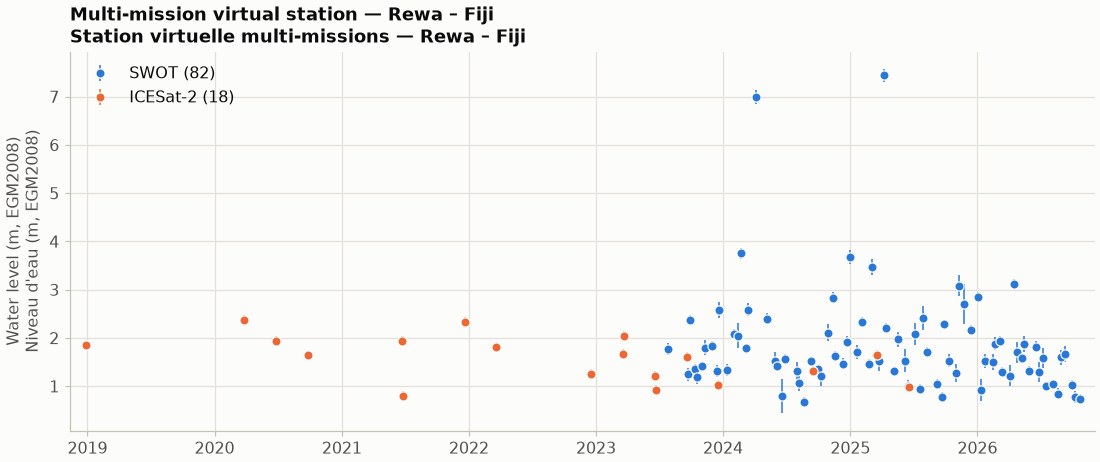

In [20]:
rewa.levels()

,pass_id,slope_m_per_km,n_points,span_km
0,2018-12-26_rgt1357,0.031,45,6.03
1,2020-09-25_rgt21,0.041,223,12.2
2,2023-03-22_rgt21,0.052,102,4.02

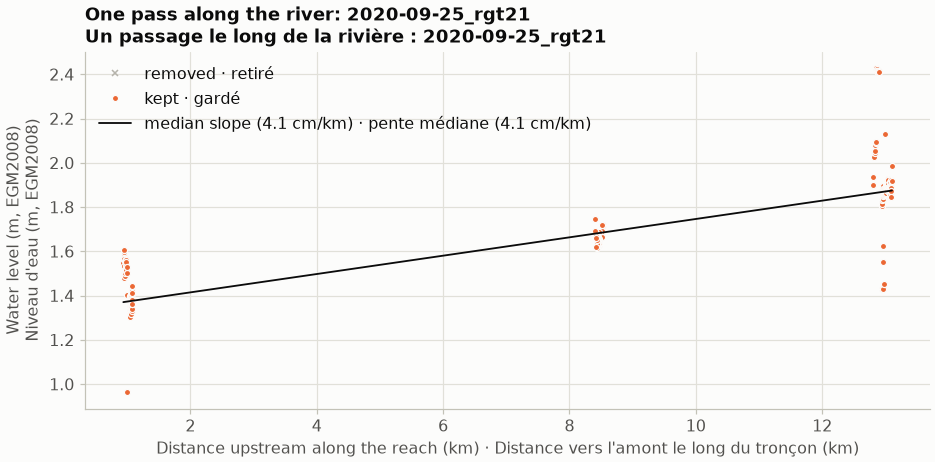

In [21]:
rewa.slope()

💬 **What do you notice?**

- One pass has a negative slope: the water surface rises towards the sea. How can the tide explain that?

> 💬 **Qu'observez-vous ?**
>
> - Un passage a une pente négative : la surface de l'eau monte vers la mer. Comment la marée peut-elle l'expliquer ?

### 3.2 SWOT and the water-flows-downhill check · SWOT et le contrôle « l'eau descend »

,Reason · Raison,Count · Nombre
0,kept · gardé,82
1,quality flag reach_q > 1 · indicateur reach_q > 1,20
2,higher than the reach upstream · plus haut que le tronçon amont,6

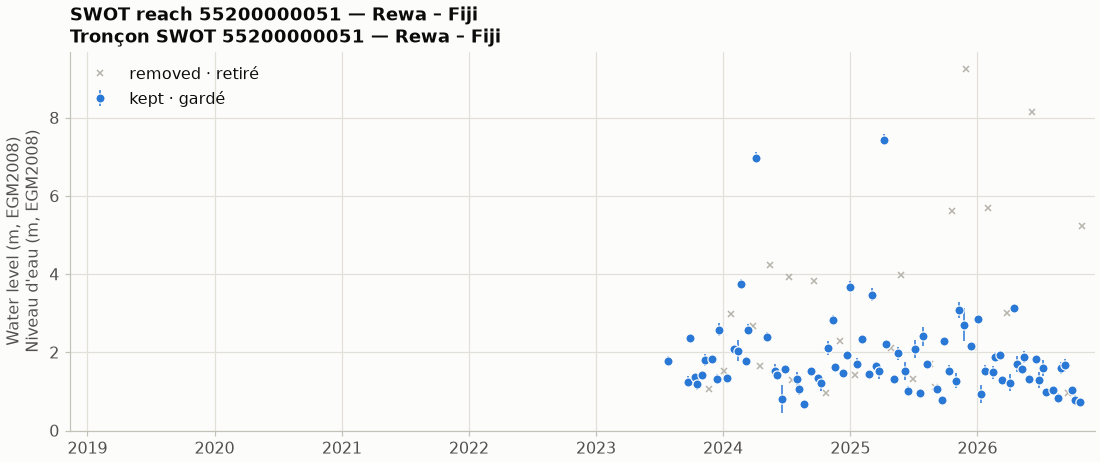

In [22]:
rewa.swot()

💬 **What do you notice?**

- Some very high SWOT values were removed because they were higher than the reach upstream. Real floods, or errors?

> 💬 **Qu'observez-vous ?**
>
> - Des valeurs SWOT très hautes ont été retirées car plus hautes que le tronçon amont. Vraies crues ou erreurs ?

### 3.3 Three reaches, from the tide upstream · Trois tronçons, de la marée vers l'amont

Three reaches of the same river · Trois tronçons de la même rivière
Nausori (tidal · marée): 40 levels, 0.16–1.74 m. · Nausori (tidal · marée) : 40 niveaux, 0.16–1.74 m.
Main · Principal (051): 82 levels, 0.68–7.44 m. · Main · Principal (051) : 82 niveaux, 0.68–7.44 m.
Upstream · Amont (061): 92 levels, 1.72–8.02 m. · Upstream · Amont (061) : 92 niveaux, 1.72–8.02 m.
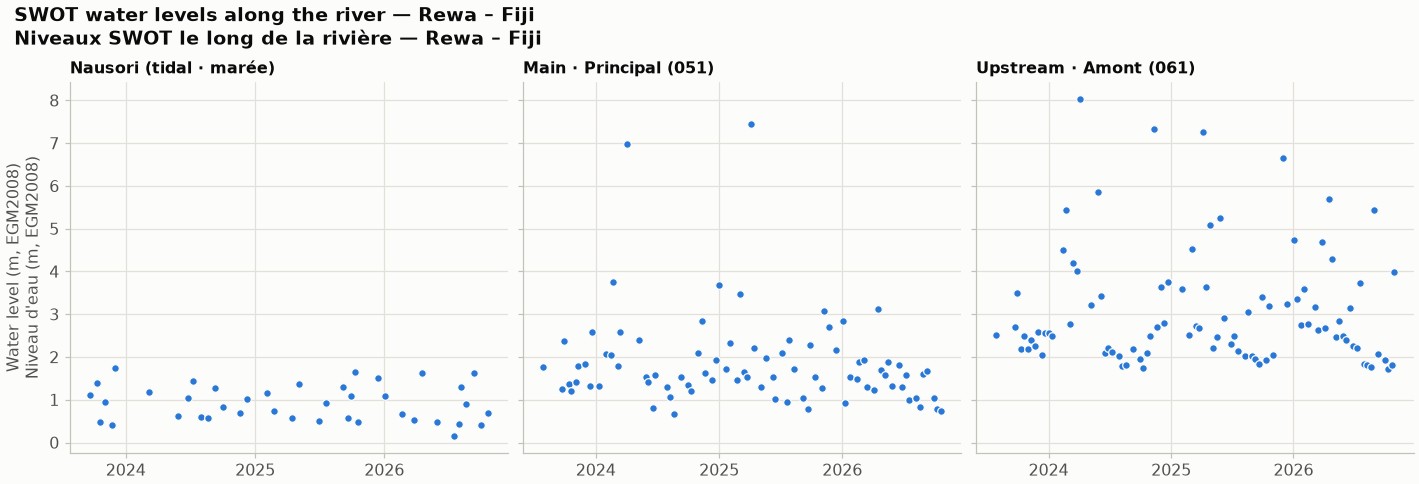

In [23]:
rewa.compare_reaches()

💬 **What do you notice?**

- Nausori stays between about 0.2 and 1.7 m all year. Why?
- Where would you put a virtual station to estimate discharge?

> 💬 **Qu'observez-vous ?**
>
> - Nausori reste entre environ 0,2 et 1,7 m toute l'année. Pourquoi ?
> - Où placeriez-vous une station virtuelle pour estimer le débit ?

### 3.4 Will a satellite see the flood? · Un satellite verra-t-il la crue ?

,1 d · j,2 d · j,3 d · j,5 d · j,10 d · j,30 d · j
Congo – Kinshasa: SWOT,5,11,16,26,48,96
Congo – Kinshasa: SWOT + ICESat-2,6,12,17,28,50,96
Rewa – Fiji: SWOT,7,14,20,34,62,97
Rewa – Fiji: SWOT + ICESat-2,7,14,21,35,63,97

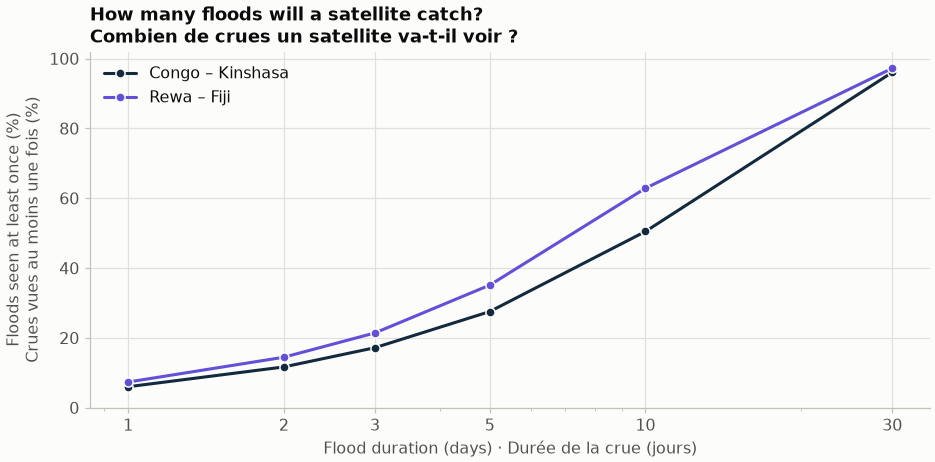

In [24]:
vg.flood_catch(congo, rewa)

💬 **What do you notice?**

- What chance does a satellite have of seeing a 1-day cyclone flood? And a 30-day Congo flood?
- What does this mean for flood warning?

> 💬 **Qu'observez-vous ?**
>
> - Quelle chance un satellite a-t-il de voir une crue cyclonique d'un jour ? Et une crue du Congo de 30 jours ?
> - Qu'est-ce que cela signifie pour l'alerte aux crues ?

### 3.5 Why no discharge? · Pourquoi pas de débit ?

In [25]:
rewa.rating()

Step 7 — Rating curve · Étape 7 — Courbe de tarage
No reference discharge for this site: there is no open discharge record and no model river is set. Add your own gauge data as data/gauge_rewa_fiji.csv (columns date, stage_m, discharge_m3s) to fit a rating curve. · Pas de débit de référence pour ce site : aucune série ouverte et aucune rivière de modèle. Ajoutez vos données dans data/gauge_rewa_fiji.csv (colonnes date, stage_m, discharge_m3s) pour ajuster une courbe.

### 3.6 Try it: no slope correction · À vous : sans correction de pente

🧪 Switch the slope correction off for the Rewa and compare the levels with the ones in 3.1.

> 🧪 Désactivez la correction de pente pour la Rewa et comparez avec les niveaux de 3.1.

,SWOT,ICESat-2,all
observations,82,18,100
first,2023-07-28,2018-12-26,2018-12-26
last,2026-10-22,2025-06-17,2026-10-22
per_year,25.4,2.8,12.8
median_gap_days,13.4,90.8,13.4
longest_gap_days,55.1,454,454

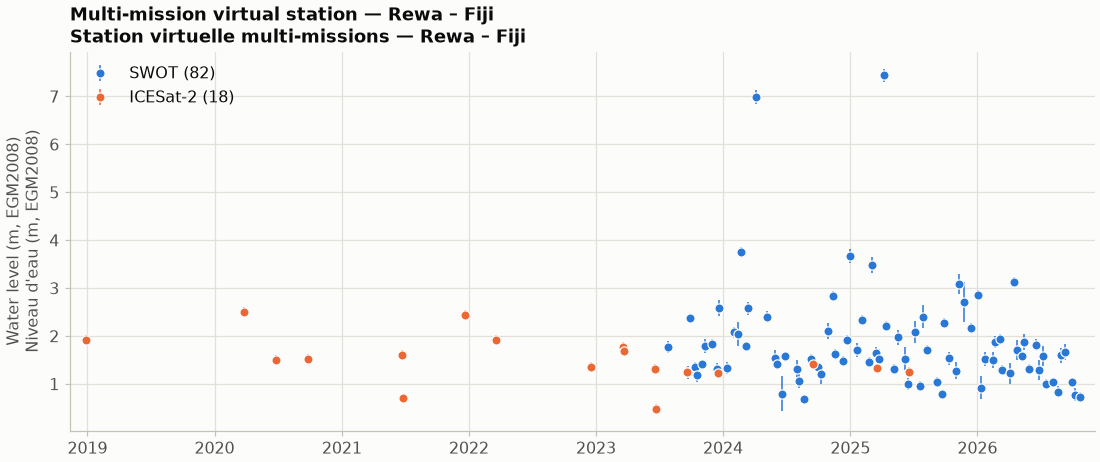

In [26]:
vg.build_station("rewa_fiji", slope_correction=False).levels()   # ✏️

## Part 4 — Explore the settings · Partie 4 — Explorer les réglages

Move the sliders and click the months. Three tasks:
1. Choose the Rewa and set **ICESat-2 max cloud** to 0. How many levels are left?
2. Set the **up/downstream tolerance** to 2 m. Do the impossible "floods" come back?
3. For Kinshasa, add March–June back one month at a time. What happens to *b* and the curve?

> Déplacez les curseurs et cliquez sur les mois. Trois tâches :
> 1. Choisissez la Rewa et mettez **ICESat-2 nuages max** à 0. Combien de niveaux restent-ils ?
> 2. Mettez la **tolérance amont/aval** à 2 m. Les « crues » impossibles reviennent-elles ?
> 3. Pour Kinshasa, remettez mars à juin un mois à la fois. Que deviennent *b* et la courbe ?

In [27]:
vg.explore()

## Part 5 — Explore more locations · Partie 5 — Explorer d'autres lieux

On every map below, **click a dot**: the station is built and its graphs appear underneath, in tabs, with the
settings and an export button. No code to copy. Orange dots are stations shipped with the package (instant,
offline); other dots download their data (internet, 20–60 s).

> Sur chaque carte ci-dessous, **cliquez sur un point** : la station est construite et ses graphiques s'affichent en
> dessous, dans des onglets, avec les réglages et un bouton d'export. Aucun code à copier. Les points orange sont des
> stations fournies avec le package (immédiat, hors ligne) ; les autres points téléchargent leurs données (internet,
> 20 à 60 s).

### 5.1 The Congo basin · Le bassin du Congo

Every dot is a SWOT river reach on the Congo and its large tributaries — a possible virtual station. Darker dots have more good SWOT levels.

> Chaque point est un tronçon SWOT du Congo et de ses grands affluents — une station virtuelle possible. Les points foncés ont plus de niveaux SWOT valides.

In [28]:
vg.explore_map()

💬 **What do you notice?**

- Click the orange pins from Kindu down to Kinshasa. How does the range of water levels change downstream?
- Open the Discharge tab for the Ubangi at Bangui. Which reference is used, and how well does the curve fit?
- In the Settings tab, switch the water-flows-downhill check off. What changes?

> 💬 **Qu'observez-vous ?**
>
> - Cliquez sur les épingles orange de Kindu jusqu'à Kinshasa. Comment l'amplitude des niveaux change-t-elle vers l'aval ?
> - Ouvrez l'onglet Débit pour l'Oubangui à Bangui. Quelle référence est utilisée, et la courbe est-elle bien ajustée ?
> - Dans l'onglet Réglages, désactivez le contrôle amont/aval. Qu'est-ce qui change ?

### 5.2 Down the river · Le long du fleuve

Water levels at seven stations, from the upper Congo (Lualaba at Kindu) to Kinshasa. Each panel shows the level minus its median.

> Les niveaux de sept stations, du haut Congo (Lualaba à Kindu) jusqu'à Kinshasa. Chaque panneau montre le niveau moins sa médiane.

Comparing stations · Comparaison de stations
Lualaba – Kindu: highest levels on average in month 5. · Lualaba – Kindu : niveaux les plus hauts en moyenne au mois 5.
Congo – Kisangani: highest levels on average in month 4. · Congo – Kisangani : niveaux les plus hauts en moyenne au mois 4.
Congo – Mbandaka: highest levels on average in month 1. · Congo – Mbandaka : niveaux les plus hauts en moyenne au mois 1.
Ubangi – Bangui: highest levels on average in month 11. · Ubangi – Bangui : niveaux les plus hauts en moyenne au mois 11.
Sangha – Ouesso: highest levels on average in month 10. · Sangha – Ouesso : niveaux les plus hauts en moyenne au mois 10.
Kasai – Kwamouth: highest levels on average in month 12. · Kasai – Kwamouth : niveaux les plus hauts en moyenne au mois 12.
Congo – Kinshasa: highest levels on average in month 12. · Congo – Kinshasa : niveaux les plus hauts en moyenne au mois 12.
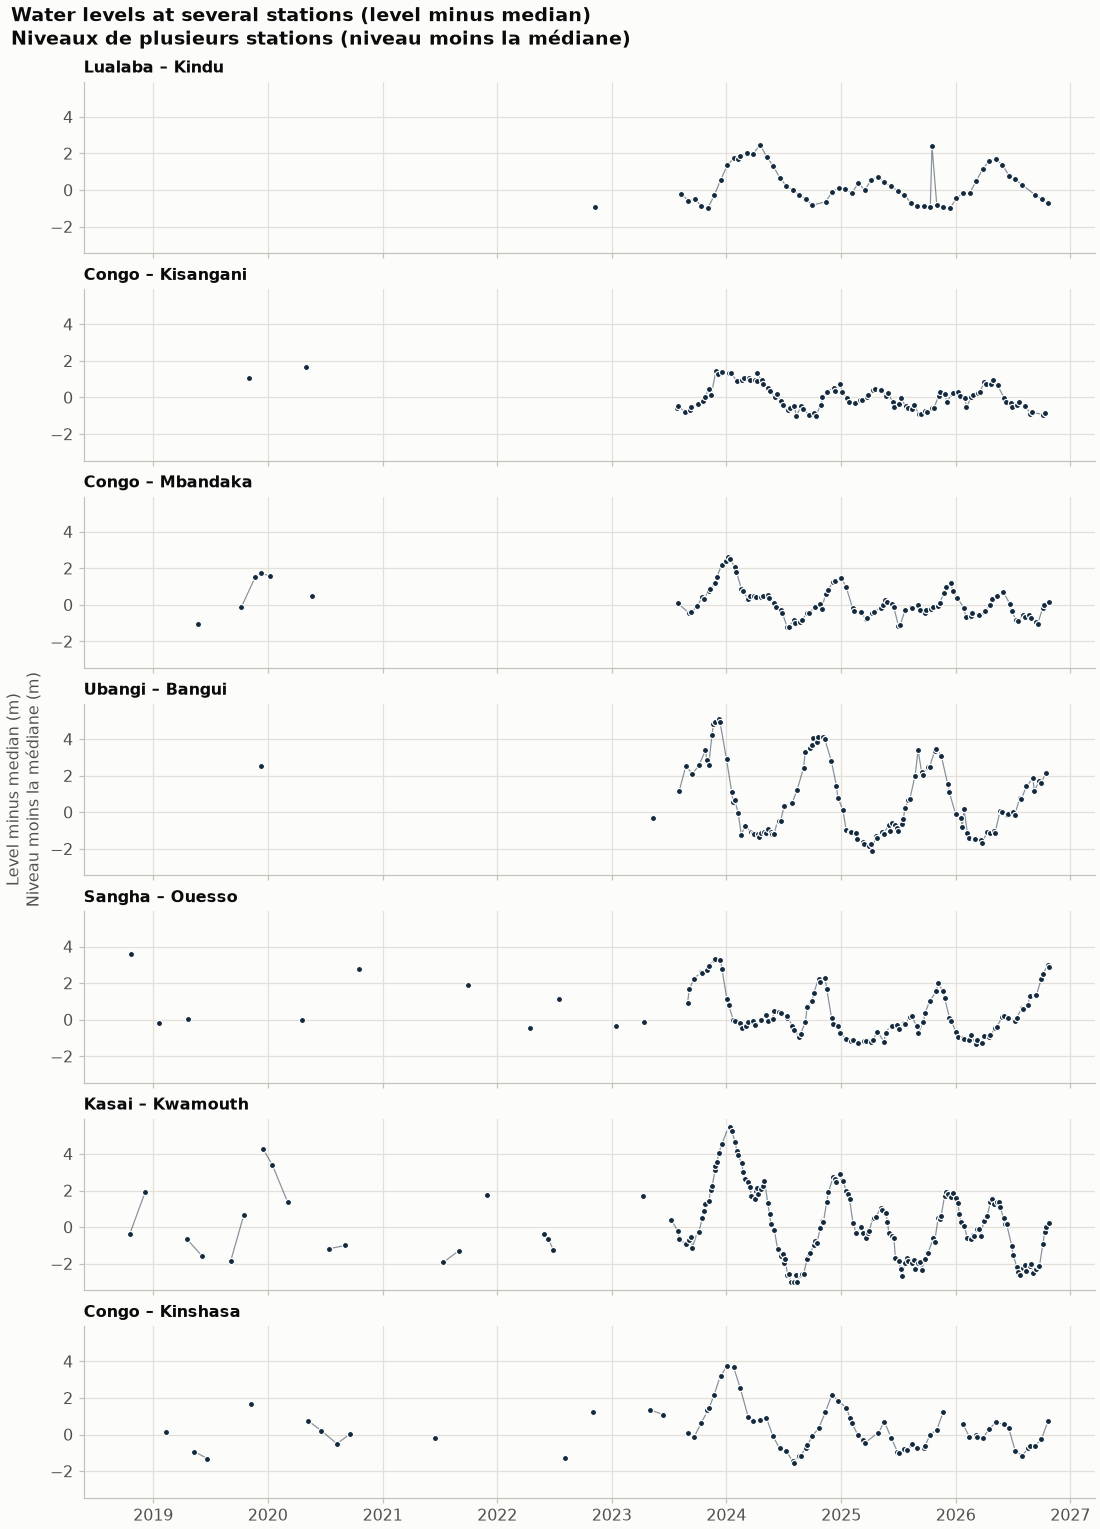

In [29]:
vg.compare_stations(["lualaba_kindu", "congo_kisangani", "congo_mbandaka", "ubangi_bangui",
                     "sangha_ouesso", "kasai_kwamouth", "congo_kinshasa"])

💬 **What do you notice?**

- Which rivers peak in October–December, and which in April–May?
- Kinshasa has two high-water seasons each year. Which tributaries explain each one?
- Which river has the biggest seasonal range?

> 💬 **Qu'observez-vous ?**
>
> - Quelles rivières culminent en octobre–décembre, et lesquelles en avril–mai ?
> - Kinshasa a deux saisons de hautes eaux par an. Quels affluents expliquent chacune ?
> - Quelle rivière a la plus grande amplitude saisonnière ?

### 5.3 Botswana

Botswana's large rivers are mostly on its borders — the Chobe, the Zambezi, the Shashe and the Limpopo — except the
Okavango, which flows in from Angola and Namibia and spreads out into its delta. Nine ready-made stations (orange) on
these five rivers work offline. The white dashed line is the border; dots up to 25 km outside it are included, so the
border rivers appear. Smaller rivers such as the Boteti and the Thamalakane at Maun are not in SWOT's river database.

> Les grands fleuves du Botswana sont surtout à ses frontières — le Chobe, le Zambèze, la Shashe et le Limpopo — sauf
> l'Okavango, qui arrive de l'Angola et de la Namibie et s'étale dans son delta. Neuf stations prêtes (orange) sur ces
> cinq fleuves fonctionnent hors ligne. La ligne blanche en tirets est la frontière ; les points jusqu'à 25 km au-delà
> sont inclus, pour montrer les fleuves frontaliers. Les petites rivières comme la Boteti et la Thamalakane à Maun ne
> figurent pas dans la base de rivières de SWOT.

In [30]:
vg.explore_map("botswana")

💬 **What do you notice?**

- Open the Okavango at Mohembo, then its Discharge tab. How does the model's mean flow compare with the mean measured at Mohembo? What would you tell a water manager who used these discharges?
- The Chobe at Kasane has no Discharge curve. Read the explanation, then compare its Levels tab with the Zambezi at Kazungula, 10 km away.
- Most Botswana dots are dark, even on narrow rivers. Does many SWOT levels always mean good levels? (Look at the Limpopo.)

> 💬 **Qu'observez-vous ?**
>
> - Ouvrez l'Okavango à Mohembo, puis son onglet Débit. Comment le débit moyen du modèle se compare-t-il à la moyenne mesurée à Mohembo ? Que diriez-vous à un gestionnaire de l'eau qui utiliserait ces débits ?
> - Le Chobe à Kasane n'a pas de courbe de débit. Lisez l'explication, puis comparez son onglet Niveaux avec le Zambèze à Kazungula, à 10 km.
> - La plupart des points du Botswana sont foncés, même sur des rivières étroites. Beaucoup de niveaux SWOT veut-il toujours dire de bons niveaux ? (Regardez le Limpopo.)

### 5.4 The Okavango, the Chobe and the Zambezi · L'Okavango, le Chobe et le Zambèze

The Okavango as it enters Botswana (Mohembo), at the end of the Panhandle (Seronga) and where the Delta opens out (Gunotsoga); the Zambezi and the Chobe where they meet at Kazungula.

> L'Okavango à son entrée au Botswana (Mohembo), au bout du Panhandle (Seronga) et à l'ouverture du Delta (Gunotsoga) ; le Zambèze et le Chobe à leur rencontre à Kazungula.

Comparing stations · Comparaison de stations
Okavango – Mohembo: highest levels on average in month 4. · Okavango – Mohembo : niveaux les plus hauts en moyenne au mois 4.
Okavango – Seronga: highest levels on average in month 5. · Okavango – Seronga : niveaux les plus hauts en moyenne au mois 5.
Okavango – Gunotsoga: highest levels on average in month 5. · Okavango – Gunotsoga : niveaux les plus hauts en moyenne au mois 5.
Zambezi – Kazungula: highest levels on average in month 5. · Zambezi – Kazungula : niveaux les plus hauts en moyenne au mois 5.
Chobe – Kasane: highest levels on average in month 5. · Chobe – Kasane : niveaux les plus hauts en moyenne au mois 5.
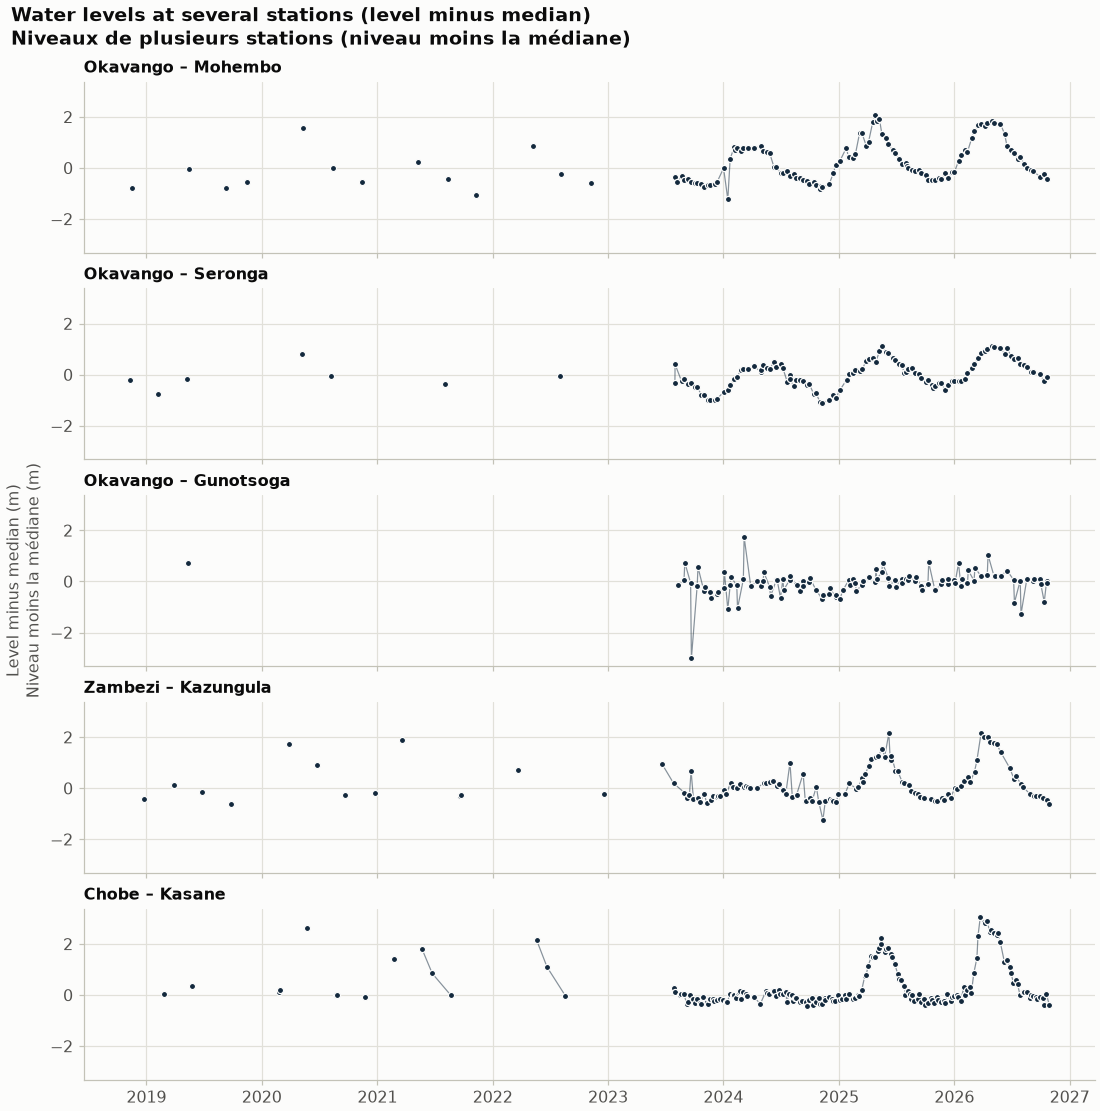

In [31]:
vg.compare_stations(["okavango_mohembo", "okavango_seronga", "okavango_gunotsoga", "zambezi_kazungula",
                     "chobe_kasane"])

💬 **What do you notice?**

- Which year had almost no flood on the Zambezi and the Chobe? What happened in southern Africa that year?
- The Okavango's yearly rise shrinks from about 2.4 m at Mohembo to 1.9 m at Seronga and 0.6 m at Gunotsoga, and peaks a month later. Where does the water go?
- The Chobe stays flat while the Zambezi is low, then rises with it. What does that mean for a rating curve at Kasane?

> 💬 **Qu'observez-vous ?**
>
> - Quelle année le Zambèze et le Chobe n'ont-ils presque pas eu de crue ? Que s'est-il passé en Afrique australe cette année-là ?
> - La montée annuelle de l'Okavango passe d'environ 2,4 m à Mohembo à 1,9 m à Seronga et 0,6 m à Gunotsoga, et culmine un mois plus tard. Où va l'eau ?
> - Le Chobe reste plat quand le Zambèze est bas, puis monte avec lui. Qu'est-ce que cela implique pour une courbe de tarage à Kasane ?

### 5.5 Down the Limpopo · Le long du Limpopo

The Limpopo is Botswana's border with South Africa and flows only part of the year. From Martin's Drift down to Pont Drift, with the Shashe — on the border with Zimbabwe — which joins it just below the Pont Drift station.

> Le Limpopo forme la frontière du Botswana avec l'Afrique du Sud et ne coule qu'une partie de l'année. De Martin's Drift jusqu'à Pont Drift, avec la Shashe — à la frontière du Zimbabwe — qui le rejoint juste en aval de la station de Pont Drift.

Comparing stations · Comparaison de stations
Limpopo – Martin's Drift: highest levels on average in month 1. · Limpopo – Martin's Drift : niveaux les plus hauts en moyenne au mois 1.
Limpopo – Zanzibar: highest levels on average in month 1. · Limpopo – Zanzibar : niveaux les plus hauts en moyenne au mois 1.
Shashe – Tuli: highest levels on average in month 12. · Shashe – Tuli : niveaux les plus hauts en moyenne au mois 12.
Limpopo – Pont Drift: highest levels on average in month 1. · Limpopo – Pont Drift : niveaux les plus hauts en moyenne au mois 1.
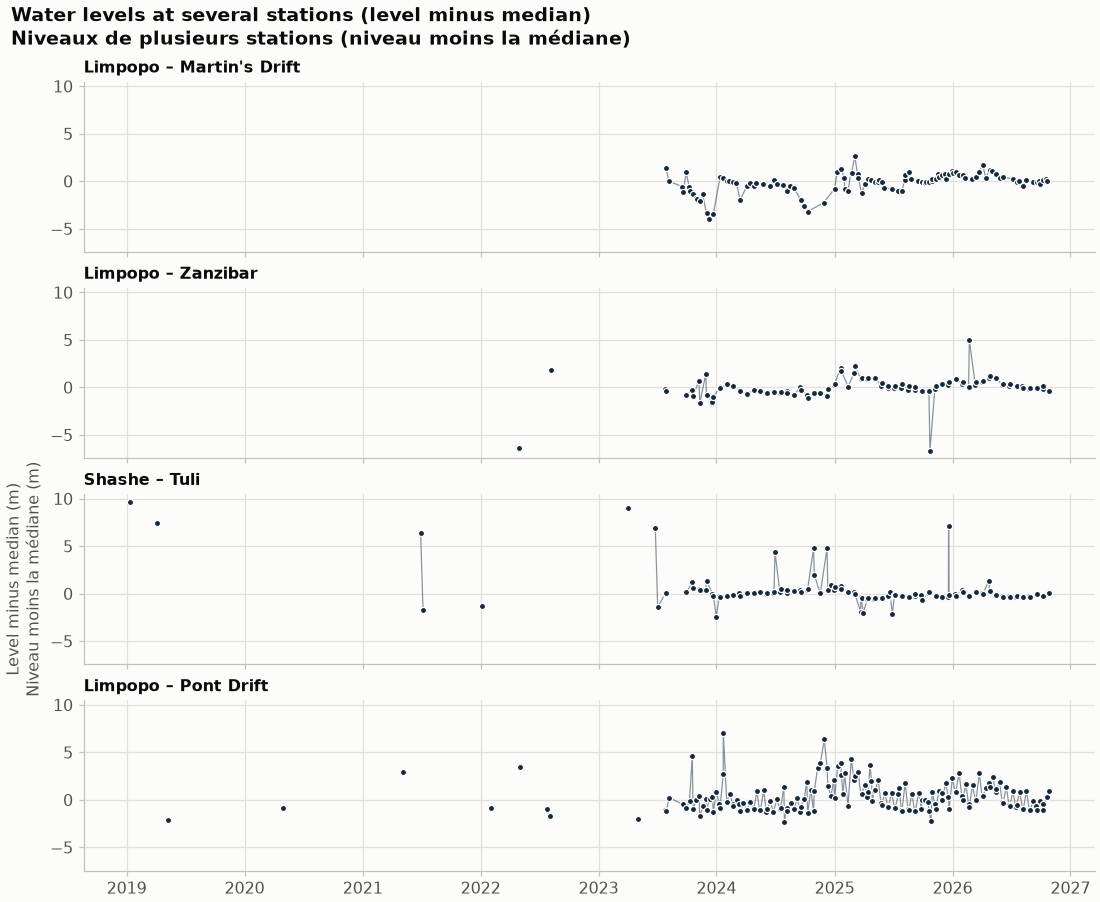

In [32]:
vg.compare_stations(["limpopo_martinsdrift", "limpopo_zanzibar", "shashe_tuli", "limpopo_pontdrift"])

💬 **What do you notice?**

- The Limpopo stations rise in January; the Okavango in 5.4 peaks in April–May. Why are the seasons so different on two rivers of the same country?
- Which panels look like a river rising and falling, and which look like noise? Compare Zanzibar with Pont Drift.
- Open the Agreement tab for the Shashe and for Pont Drift on the map in 5.3: the two satellites differ by about 4 m and 2 m. What could each one be measuring when the sand bed is almost dry?

> 💬 **Qu'observez-vous ?**
>
> - Les stations du Limpopo montent en janvier ; l'Okavango en 5.4 culmine en avril–mai. Pourquoi les saisons sont-elles si différentes sur deux fleuves du même pays ?
> - Quels panneaux ressemblent à une rivière qui monte et descend, et lesquels à du bruit ? Comparez Zanzibar et Pont Drift.
> - Ouvrez l'onglet Accord de la Shashe et de Pont Drift sur la carte de 5.3 : les deux satellites diffèrent d'environ 4 m et 2 m. Que pourrait mesurer chacun quand le lit de sable est presque à sec ?

### 5.6 Any river in the world · N'importe quelle rivière du monde

The map starts with the world's largest rivers. **Zoom in anywhere** and every SWOT reach in the view appears — up to
3,000 at a time, widest first; the line under the map says whether all of them are shown. So every possible location
in the world can be found and clicked. Orange dots are ready-made examples on every continent — from the Niger and
the Amazon to the Karnali in Nepal, the Cimanuk in West Java and the Mississippi; they open instantly, offline.

> La carte commence par les plus grands fleuves du monde. **Zoomez n'importe où** et chaque tronçon SWOT de la vue
> apparaît — 3 000 au plus à la fois, les plus larges d'abord ; la ligne sous la carte indique s'ils sont tous affichés.
> On peut donc trouver et cliquer n'importe quel lieu possible dans le monde. Les points orange sont des exemples prêts
> sur tous les continents — du Niger et de l'Amazone à la Karnali au Népal, à la Cimanuk à Java occidental et au
> Mississippi ; ils s'ouvrent tout de suite, hors ligne.

In [33]:
vg.explore_map("world")

💬 **What do you notice?**

- Zoom in on your own country. Which rivers have SWOT reaches? Click one near a gauge you know (internet needed).
- Open two examples on different continents. Which has the biggest seasonal range, and in which months does each peak?
- Which example does SWOT see most often (Levels tab)? Why might rivers far from the equator be seen more often?
- For an example with a Discharge tab, is the curve good enough to replace a ground gauge? What would you check first?
- Open the Karnali (Nepal) and the Cimanuk (West Java). When is each river highest, and why? Why does the Cimanuk stay near 24 m in the dry season — and what happened at the end of 2023?

> 💬 **Qu'observez-vous ?**
>
> - Zoomez sur votre propre pays. Quelles rivières ont des tronçons SWOT ? Cliquez sur l'un d'eux près d'une station que vous connaissez (internet nécessaire).
> - Ouvrez deux exemples sur des continents différents. Lequel a la plus grande amplitude saisonnière, et en quels mois chacun culmine-t-il ?
> - Quel exemple SWOT voit-il le plus souvent (onglet Niveaux) ? Pourquoi les rivières loin de l'équateur seraient-elles vues plus souvent ?
> - Pour un exemple avec un onglet Débit, la courbe suffit-elle pour remplacer une station au sol ? Que vérifieriez-vous d'abord ?
> - Ouvrez la Karnali (Népal) et la Cimanuk (Java occidental). Quand chaque rivière est-elle au plus haut, et pourquoi ? Pourquoi la Cimanuk reste-t-elle vers 24 m en saison sèche — et que s'est-il passé fin 2023 ?

### 5.7 Straight to your region · Directement à votre région

To jump straight to a region, give a point and a radius — here the Rewa in Fiji. Change the numbers to your own river, then click a dot. This map also reloads the reaches when you pan or zoom.

> Pour aller directement à une région, donnez un point et un rayon — ici la Rewa aux Fidji. Mettez les nombres de votre propre rivière, puis cliquez sur un point. Cette carte recharge aussi les tronçons quand vous vous déplacez ou zoomez.

In [34]:
vg.explore_map(lat=-17.96, lon=178.43, radius_km=150)   # ✏️ your region · votre région

## Part 6 — Summary · Partie 6 — Résumé

- Satellites give water levels above the **EGM2008 geoid**; your gauge reads from its own zero.
- **Cleaning** makes the station: a narrow water mask, slope correction, and the "water flows downhill" check.
- A rating curve is only as good as its **reference discharge** — and satellite levels can expose a biased model.
- Large, slow rivers suit altimetry; small, flashy, tidal rivers still need ground gauges.

For the full method and code, see the trainer notebook `Virtual_River_Gauges_DRC_Fiji.ipynb`.

> - Les satellites donnent des niveaux au-dessus du **géoïde EGM2008** ; votre échelle lit depuis son propre zéro.
> - Le **nettoyage** fait la station : masque d'eau étroit, correction de pente, et contrôle « l'eau descend ».
> - Une courbe de tarage ne vaut que son **débit de référence** — et les niveaux satellitaires peuvent révéler un modèle biaisé.
> - Les grands fleuves lents se prêtent à l'altimétrie ; les petites rivières rapides et à marée ont toujours besoin de stations au sol.
>
> Pour la méthode complète et le code, voir le notebook formateur `Virtual_River_Gauges_DRC_Fiji.ipynb`.

In [35]:
vg.credits()

Data: ICESat-2 ATL13 v007 (NASA/NSIDC, doi:10.5067/ATLAS/ATL13.007) via SlideRule Earth; SWOT RiverSP Version D (NASA/CNES, PO.DAAC) via Hydrocron; GEOGloWS v2 (ECMWF); SWORD v17b river database (Altenau et al. 2021, CC BY 4.0); Botswana border: Natural Earth (public domain). Optional: GRDC, DAHITI (CC BY 4.0). · Données : ICESat-2 ATL13 v007 (NASA/NSIDC, doi:10.5067/ATLAS/ATL13.007) via SlideRule Earth ; SWOT RiverSP Version D (NASA/CNES, PO.DAAC) via Hydrocron ; GEOGloWS v2 (ECMWF) ; base de rivières SWORD v17b (Altenau et al. 2021, CC BY 4.0) ; frontière du Botswana : Natural Earth (domaine public). Facultatif : GRDC, DAHITI (CC BY 4.0).